# Hybrid Video Recommendations on VK-LSVD

Bogdan Pravdukhin · Offline ranking experiment

Install the dependencies from `requirements.txt` before running the notebook. The saved tables and figures show the original run.

## План проекта

**7 июля:** постановка задачи, выбор моделей и метрик.  
**8 июля:** загрузка, EDA, подготовка данных.  
**9 июля:** baseline-модели `Popularity`, `ItemKNN`, `ALS`.  
**10-11 июля:** content-based и hybrid модели.  
**12 июля:** cold-start, устойчивость, итоговые таблицы и графики.


In [3]:
from pathlib import Path
import math
import random
import shutil
import warnings
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy import sparse
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from huggingface_hub import hf_hub_download

warnings.filterwarnings('ignore')

try:
    from implicit.als import AlternatingLeastSquares
    HAS_IMPLICIT = True
except ImportError as e:
    raise ImportError('Install the dependencies from requirements.txt to run ALS.') from e

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

DATASET_ID = 'deepvk/VK-LSVD'
SUBSAMPLE = 'up0.001_ip0.001'
DATA_DIR = Path('./data/VK-LSVD')
OUTPUT_DIR = Path('./outputs')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

#так как выполняю в колабе буду начинать с последней недели потому что при большей обработке RAM не хватает.
#сначала пытался работать с первыми неделями, но из-за этого ключевые метрики не считались. Потом пробовал с 5 последними неделями, там падал RAM
TRAIN_WEEKS = [24]
VALIDATION_WEEK = 25
MAX_ROWS_PER_WEEK = 250_000
MAX_EVAL_USERS = 1200
K_VALUES = [10, 20]
EMBEDDING_SIZES = [8, 16, 32, 64]

print('Subsample:', SUBSAMPLE)
print('Train weeks:', TRAIN_WEEKS)
print('Validation week:', VALIDATION_WEEK)
print('Max rows per week:', MAX_ROWS_PER_WEEK)

# 7 июля: постановка задачи

Сравниваем чистую коллаборативную фильтрацию и модели, которые используют content embeddings объектов.

Модели:

1. `Popularity`;
2. `ItemKNN`;
3. `ALS`;
4. `ContentKNN`;
5. гибриды `ItemKNN + ContentKNN` и `ALS + ContentKNN`.

Метрики: `Recall@K`, `NDCG@K`, `HitRate@K`, `Coverage@20`, отдельно cold-start анализ.


# 8 июля: загрузка данных и EDA

Скачиваем только нужные файлы и читаем только нужные колонки. Это сильно экономит память Colab.


In [4]:
train_files = [f'subsamples/{SUBSAMPLE}/train/week_{week:02}.parquet' for week in TRAIN_WEEKS]
validation_file = f'subsamples/{SUBSAMPLE}/validation/week_{VALIDATION_WEEK:02}.parquet'
metadata_files = ['metadata/items_metadata.parquet', 'metadata/item_embeddings.npz']
for file_name in train_files + [validation_file] + metadata_files:
    local_path = hf_hub_download(repo_id=DATASET_ID, repo_type='dataset', filename=file_name, local_dir=DATA_DIR)
    print('downloaded:', local_path)

In [5]:
MODEL_COLUMNS = ['user_id', 'item_id', 'timespent', 'like', 'dislike', 'share', 'bookmark', 'click_on_author', 'open_comments']
def parquet_columns(path):
  return list(pl.read_parquet_schema(path).keys()) #для отсмотра схему parquet-файла без полной загрузки

def read_week_light(path):
  available = parquet_columns(path) #чтобы использовались только доступные нужные колонки
  cols = [c for c in MODEL_COLUMNS if c in available]
  lf = pl.scan_parquet(path).select(cols)
  if MAX_ROWS_PER_WEEK is not None:
      lf = lf.head(MAX_ROWS_PER_WEEK) #чтобы RAM не падал
  return lf.with_columns(pl.lit(path.stem).alias('source_week'))
train_paths = [DATA_DIR / file_name for file_name in train_files]
train_lazy_parts = [read_week_light(path) for path in train_paths]

try: #для экономии памяти
    train_day2 = pl.concat(train_lazy_parts).collect(engine='streaming')
except TypeError:
    train_day2 = pl.concat(train_lazy_parts).collect(streaming=True)
valid_path = DATA_DIR / validation_file
valid_cols = [c for c in MODEL_COLUMNS if c in parquet_columns(valid_path)]
valid_day2 = pl.read_parquet(valid_path, columns=valid_cols)

# Метаданные читаем отдельно. Если RAM мало, users/items metadata можно не использовать дальше.
items_metadata = pl.read_parquet(DATA_DIR / 'metadata/items_metadata.parquet')
emb_npz = np.load(DATA_DIR / 'metadata/item_embeddings.npz')
id_key = 'item_id' if 'item_id' in emb_npz.files else [k for k in emb_npz.files if 'item' in k.lower()][0]
emb_key = 'embedding' if 'embedding' in emb_npz.files else [k for k in emb_npz.files if emb_npz[k].ndim == 2][0]
embedding_item_ids = emb_npz[id_key]
item_embeddings = emb_npz[emb_key].astype(np.float32)

print('train:', train_day2.shape)
print('validation:', valid_day2.shape)
print('items metadata:', items_metadata.shape)
print('item embeddings:', item_embeddings.shape)
print('train columns:', train_day2.columns)

In [6]:
def dataset_summary(df, name): #подсчет размеров датасета
  users = df.select(pl.col('user_id').n_unique()).item()
  items = df.select(pl.col('item_id').n_unique()).item()
  interactions = df.height
  density = interactions / (users * items) if users and items else 0 #плотность в нашем случае показывает какая доля user-item матрицы заполнена
  return {'split': name, 'users': users, 'items': items, 'interactions': interactions, 'density': density}

summary_df = pd.DataFrame([dataset_summary(train_day2, 'train'), dataset_summary(valid_day2, 'validation')])
summary_df.to_csv(OUTPUT_DIR / 'dataset_summary.csv', index=False) #нужно для отчета
summary_df

,split,users,items,interactions,density
0,train,9741,8089,250000,0.003173
1,validation,9904,9052,519839,0.005798


In [7]:
#также нужно понимать статистику по  train неделе. Если использовать несколько недель это будет полезно для сравнения
week_summary = (train_day2.group_by('source_week').agg([pl.len().alias('interactions'), pl.col('user_id').n_unique().alias('users'), pl.col('item_id').n_unique().alias('items'),]).sort('source_week').to_pandas())
week_summary.to_csv(OUTPUT_DIR / 'week_summary.csv', index=False)
week_summary


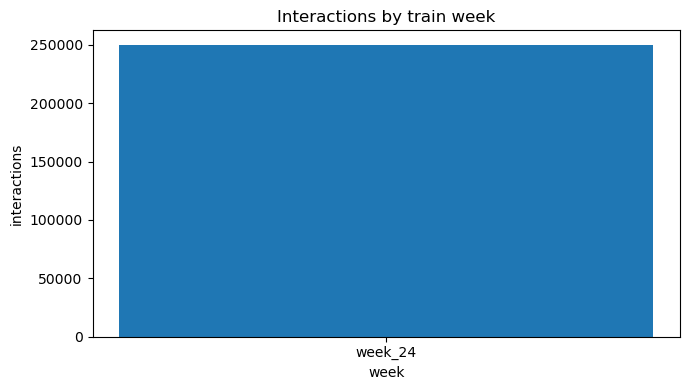

In [8]:
#эта визуализация была добавлена на начальных этапах работы, когда недель было несколько. Так как в финале одна, график становится не сильно полезным. Все же для будщего масштабирования будет полезно проверить выбросы среди недель
plt.figure(figsize=(7, 4))
plt.bar(week_summary['source_week'], week_summary['interactions'])
plt.title('Interactions by train week')
plt.xlabel('week')
plt.ylabel('interactions')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'interactions_by_week.png', dpi=160) #для отчета. Все следующие сохранения данных будут применяться в отчете
plt.show()

In [9]:
user_activity = train_day2.group_by('user_id').agg(pl.len().alias('n_interactions')) #подсчет взаимодествий пользователей
item_activity = train_day2.group_by('item_id').agg(pl.len().alias('n_interactions')) #популярность каждого объекта

user_activity_pd = user_activity.to_pandas() #для графиков
item_activity_pd = item_activity.to_pandas()

print('User activity')
display(user_activity_pd['n_interactions'].describe())
print('Item activity')
display(item_activity_pd['n_interactions'].describe())
#это нужно чтобы посмотреть насколько сильно различается популярность объектов. Неравномерность и разреженность

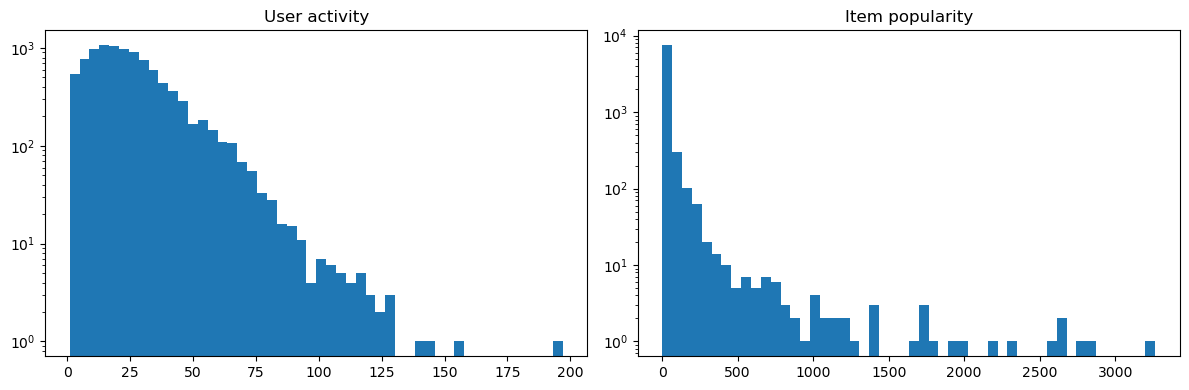

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(user_activity_pd['n_interactions'], bins=50)
axes[0].set_title('User activity')
axes[0].set_yscale('log') #лог шкала нужна потому что много пользователей/объектов с малым числом событий и мало очень активных.
axes[1].hist(item_activity_pd['n_interactions'], bins=50)
axes[1].set_title('Item popularity')
axes[1].set_yscale('log')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'activity_histograms.png', dpi=160)
plt.show()

# Подготовка train/validation

Здесь два важных исправления:

1. boolean feedback сначала приводится к `Float32`, а уже потом заполняются пропуски;
2. validation берём только по позитивным событиям.


In [11]:
def safe_float(col_name):
    # Polars сначала не работал потмоу что bool-колонку я занулял числом. Поэтому порядок именно такой: cast потом fill_null.
  return pl.col(col_name).cast(pl.Float32, strict=False).fill_null(0.0)


def add_interaction_weight(df):
  expr = pl.lit(1.0, dtype=pl.Float32) # Базово каждое взаимодействие имеет вес 1. Дальше усиливаем его, если пользователь сделал более явное положительное действие.
  if 'like' in df.columns:
      expr = expr + 2.0 * safe_float('like')
  if 'bookmark' in df.columns:
      expr = expr + 2.0 * safe_float('bookmark')
  if 'share' in df.columns:
      expr = expr + 1.5 * safe_float('share')
  if 'dislike' in df.columns:
      expr = expr - 1.0 * safe_float('dislike') #уменьшаем потому что отрицательный сигнал
  if 'timespent' in df.columns:
      expr = expr + 0.15 * safe_float('timespent').clip(0.0, 600.0).log1p() #сначала слишком длинные просмотры доминировали в весе. Нашел выход через clip, который ставит ограничения
  return df.with_columns(expr.clip(0.1, 10.0).alias('weight'))

def make_positive_validation(df):
  positive = pl.lit(False) #только положительные события
  if 'like' in df.columns:
      positive = positive | pl.col('like').fill_null(False).cast(pl.Boolean, strict=False)
  if 'bookmark' in df.columns:
      positive = positive | pl.col('bookmark').fill_null(False).cast(pl.Boolean, strict=False)
  if 'share' in df.columns:
      positive = positive | pl.col('share').fill_null(False).cast(pl.Boolean, strict=False)
  if 'timespent' in df.columns:
      positive = positive | (safe_float('timespent') >= 10.0)
  return df.filter(positive)

train_model = add_interaction_weight(train_day2) #добавляем числовой вес взаимодействия в train
valid_positive = make_positive_validation(valid_day2) #только положительные события
train_users = train_model.select('user_id').unique().to_numpy().reshape(-1) #собираем пользователей и объекты, которые есть в train потому что модель не сможет рекомендовать объекты, которые она не видела при обучении
train_items = train_model.select('item_id').unique().to_numpy().reshape(-1)
train_user_set = set(train_users.tolist())
train_item_set = set(train_items.tolist())
valid_candidate = valid_positive.filter(pl.col('user_id').is_in(train_user_set) & pl.col('item_id').is_in(train_item_set)) #validation только для train
train_pairs = train_model.select(['user_id', 'item_id']).unique()
valid_model = valid_candidate.join(train_pairs, on=['user_id', 'item_id'], how='anti') #для оценки именно новых рекомендаций, а не просмотренных

print('train_model:', train_model.shape)
print('valid_positive:', valid_positive.shape)
print('valid_candidate user/item overlap:', valid_candidate.shape)
print('valid_model after removing seen pairs:', valid_model.shape)

In [12]:
# Диагностика чтобы не ловить нулевые метрики вслепую.
train_items_set = set(train_model.select('item_id').unique().to_numpy().reshape(-1))
valid_items_set = set(valid_day2.select('item_id').unique().to_numpy().reshape(-1))
valid_filtered_items_set = set(valid_model.select('item_id').unique().to_numpy().reshape(-1))

print('Train items:', len(train_items_set))
print('Validation items:', len(valid_items_set))
print('Validation items after filter:', len(valid_filtered_items_set))
print('Raw item overlap:', len(train_items_set & valid_items_set))
print('Raw overlap share:', len(train_items_set & valid_items_set) / max(1, len(valid_items_set)))
print('Filtered overlap share:', len(train_items_set & valid_filtered_items_set) / max(1, len(valid_filtered_items_set)))

valid_pairs = valid_model.select(['user_id', 'item_id'])
seen_again = valid_pairs.join(train_pairs, on=['user_id', 'item_id'], how='inner')
print('Validation pairs:', valid_pairs.height)
print('Validation pairs already seen in train:', seen_again.height)
print('Seen share:', seen_again.height / max(1, valid_pairs.height))

In [13]:
# Сравниваем top-100 самых популярных объектов в train и validation. Если пересечение маленькое, значит популярность сильно изменилась между неделями. В таком случае Popularity@20 может быть нулевой не из-за бага, а потому что популярные в train объекты уже не популярны в validation.
train_top = set(train_model.group_by('item_id').agg(pl.len().alias('cnt')).sort('cnt', descending=True).head(100).select('item_id').to_numpy().reshape(-1))
valid_top = set(valid_model.group_by('item_id').agg(pl.len().alias('cnt')).sort('cnt', descending=True).head(100).select('item_id').to_numpy().reshape(-1))

print('Top-100 popularity overlap:', len(train_top & valid_top))
print('Overlap share:', len(train_top & valid_top) / 100)

In [14]:
user_ids = train_users
item_ids = train_items #списки пользователей и объектов порядок строк и столбцов в матрице user-item
user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)} #sparse матрица не умеет работать с произвольными индексами поэтому приводим их во внутренние 0,1,2,...
idx_to_item = {idx: item_id for item_id, idx in item_to_idx.items()} #обратный словарь чтобы после рекомендаций вернуть item_id обратно

train_pd = train_model.select(['user_id', 'item_id', 'weight']).to_pandas()
rows = train_pd['user_id'].map(user_to_idx).to_numpy()
cols = train_pd['item_id'].map(item_to_idx).to_numpy()
values = train_pd['weight'].astype(np.float32).to_numpy()

user_item_matrix = sparse.csr_matrix((values, (rows, cols)), shape=(len(user_ids), len(item_ids))) #строки-пользователи, столбцы-объекты
user_item_matrix.sum_duplicates()
#вообще используется sparse матрица потому что обычная плотная матрица была слишком большой
binary_user_item_matrix = user_item_matrix.copy()
binary_user_item_matrix.data = np.ones_like(binary_user_item_matrix.data, dtype=np.float32)# бинарная весрия для itemknn
item_user_matrix = binary_user_item_matrix.T.tocsr() #транспонированная матрица для поиска похожих объектов

print('user_item_matrix:', user_item_matrix.shape)
print('nnz:', user_item_matrix.nnz)

In [15]:
def make_user_dict_from_validation(valid_df):
  valid_pd = valid_df.select(['user_id', 'item_id']).to_pandas() # для каждого пользователя собираем множество релевантных объектов из validation
  return valid_pd.groupby('user_id')['item_id'].apply(lambda x: set(x)).to_dict() #потом будем проверять попала ли рекомендация правильные айтемы

relevant_by_user = make_user_dict_from_validation(valid_model) #объекты, которые пользователь реально выбрал в валидацию
seen_by_user = {} #объекты, которые пользватель уже видел в train. Их не надо рекомендовать

coo = binary_user_item_matrix.tocoo() #чтобы пройтись по всем ненулевым элементам матрицы
for u_idx, i_idx in zip(coo.row, coo.col):
  user_id = user_ids[u_idx]
  item_id = idx_to_item[i_idx]
  seen_by_user.setdefault(user_id, set()).add(item_id)

candidate_users = [u for u in relevant_by_user if u in train_user_set] # оценка только тех пользователей, которые есть и в validation и в train
if MAX_EVAL_USERS is not None and len(candidate_users) > MAX_EVAL_USERS: #случайная подвыборка чтобы объективно оценить
  rng = np.random.default_rng(RANDOM_SEED)
  candidate_users = rng.choice(candidate_users, size=MAX_EVAL_USERS, replace=False).tolist()

print('Users for evaluation:', len(candidate_users))

In [16]:
def dcg_at_k(recommended, relevant, k): #чем выше релевантный объект в списке тем больше вклад в score
  score = 0.0
  for rank, item_id in enumerate(recommended[:k], start=1):
      if item_id in relevant:
          score += 1.0 / math.log2(rank + 1)
  return score

def ndcg_at_k(recommended, relevant, k): #нормировка
  ideal_hits = min(len(relevant), k)
  if ideal_hits == 0:
      return 0.0
  ideal = sum(1.0 / math.log2(rank + 1) for rank in range(1, ideal_hits + 1)) #идеальный случай это когда все релевантные объекты стоят в верху списка
  return dcg_at_k(recommended, relevant, k) / ideal

def evaluate_recommender(name, recommend_func, users, relevant_dict, k_values=K_VALUES, cold_items=None): #функция оценки модели
  rows = []
  recommended_at_20 = set() #топ-20 рекомендация

  for user_id in tqdm(users, desc=f'evaluating {name}'):
      relevant = relevant_dict.get(user_id, set())
      if not relevant: #пропуск если нет релевантных объектов потому что тогда нельзя ничего оценить
          continue

      max_k = max(k_values) # получаем рекомендации один раз на максимальный К
      recommended = recommend_func(user_id, max_k)
      recommended_at_20.update(recommended[:20])

      row = {'model': name, 'user_id': user_id}
      for k in k_values:
          rec_k = recommended[:k]
          hits = len(set(rec_k) & relevant) #сколько рекомендованных объектов реально есть в validation
          row[f'recall@{k}'] = hits / len(relevant) # какую долю релевантных объектов нашли в top-K
          row[f'hitrate@{k}'] = float(hits > 0) # был ли хотя бы один правильный объект в top-K
          row[f'ndcg@{k}'] = ndcg_at_k(rec_k, relevant, k) #насколько высоко в списке стоят релевантные объекты

          if cold_items is not None: # отдельный подсчет recall только по редким объектам
              cold_relevant = relevant & cold_items
              row[f'cold_recall@{k}'] = np.nan if not cold_relevant else len(set(rec_k) & cold_relevant) / len(cold_relevant)

      rows.append(row)

  per_user = pd.DataFrame(rows)
  summary = {'model': name, 'n_eval_users': len(per_user)}

  for k in k_values: #подсчет средних метрик
      for metric in ['recall', 'hitrate', 'ndcg']:
          summary[f'{metric}@{k}'] = per_user[f'{metric}@{k}'].mean() if len(per_user) else 0.0
      if cold_items is not None:
          summary[f'cold_recall@{k}'] = per_user[f'cold_recall@{k}'].mean() if len(per_user) else 0.0

  summary['coverage@20'] = len(recommended_at_20) / len(item_ids) if len(item_ids) else 0.0 # Coverage@20 показывает, какую долю каталога модель вообще умеет рекомендовать
  return summary, per_user
# Чем выше coverage, тем разнообразнее рекомендации

# 9 июля: baseline-модели


In [17]:
item_popularity = (train_model.group_by('item_id').agg(pl.col('weight').sum().alias('score')).sort('score', descending=True).to_pandas()) #рекомендация популярных объектов
#популярность считается как сумма всех весов взаимодействий по каждому объекту
popular_items = item_popularity['item_id'].tolist()

def recommend_popularity(user_id, k=20):
  seen = seen_by_user.get(user_id, set())
  result = []
  for item_id in popular_items:
      if item_id not in seen:
          result.append(item_id)
      if len(result) >= k: #остановка после набора k рекомендаций
          break
  return result

pop_summary, pop_per_user = evaluate_recommender('Popularity', recommend_popularity, candidate_users, relevant_by_user) #оценка
pop_summary

In [18]:
# Проверка: если @20 нули, смотрим, появляется ли сигнал на больших k
for big_k in [20, 50, 100, 200, 500]:
  summary, _ = evaluate_recommender(f'Popularity@{big_k}', lambda user_id, k, real_k=big_k: recommend_popularity(user_id, real_k), candidate_users, relevant_by_user, k_values=[big_k])
  print(summary)


In [19]:
ITEMKNN_NEIGHBORS = 60
item_knn = NearestNeighbors(n_neighbors=min(ITEMKNN_NEIGHBORS + 1, item_user_matrix.shape[0]), metric='cosine', algorithm='brute') # +1 нужен потому что самым близким соседом объект обычно является сам для себя
item_knn.fit(item_user_matrix) #матрица объект x пользователь
item_distances, item_neighbors = item_knn.kneighbors(item_user_matrix, return_distance=True)
item_similarities = 1.0 - item_distances #формула для similarity
print('ItemKNN ready:', item_neighbors.shape)


In [20]:
def recommend_itemknn(user_id, k=20):
  if user_id not in user_to_idx: #если пользователь не встречался персональную рекомендацию построить нельзя поэтому берется по популярности
      return recommend_popularity(user_id, k)

  u_idx = user_to_idx[user_id]
  seen_indices = binary_user_item_matrix[u_idx].indices #берем индексы с которыми пользователь уже взаимодейстовавал
  seen = seen_by_user.get(user_id, set()) #чтобы не рекомендовать уже просмотренные объекты повторно
  scores = {} #хранение scores
  for seen_idx in seen_indices:
      for neighbor_idx, sim in zip(item_neighbors[seen_idx], item_similarities[seen_idx]):
          if neighbor_idx == seen_idx:  #пропуск если объект похож сам на себя
              continue
          item_id = idx_to_item[int(neighbor_idx)]
          if item_id in seen: #пропуск если объект уже был
              continue
          scores[item_id] = scores.get(item_id, 0.0) + float(sim)

  if not scores: #если ничего не нашлось возврат к popularity baseline
      return recommend_popularity(user_id, k)

  ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True) #сортировка
  return [item_id for item_id, score in ranked[:k]]

itemknn_summary, itemknn_per_user = evaluate_recommender('ItemKNN', recommend_itemknn, candidate_users, relevant_by_user) #оценка
itemknn_summary


In [21]:
# в первой версии использовалась траспонированная матрица user-item. Это ломало код потому что это ломало соответствие индексов
als_model = None
if HAS_IMPLICIT:
  als_model = AlternatingLeastSquares(factors=48, regularization=0.08, iterations=15, random_state=RANDOM_SEED) #ALS - матричная факторизация по implicit feedback. 1) 48- число скрытых факторов 2) регуляризация чтобы модель не переобучалась
  als_model.fit(user_item_matrix)
  print('ALS fitted')
else:
  print('ALS skipped')


def recommend_als(user_id, k=20):
  if not HAS_IMPLICIT or als_model is None or user_id not in user_to_idx: # если ALS недоступен используем itemknn
    return recommend_itemknn(user_id, k)

  u_idx = user_to_idx[user_id]
  ids, scores = als_model.recommend(userid=u_idx, user_items=user_item_matrix[u_idx], N=k, filter_already_liked_items=True) #filter_already_liked_items=True убирает объекты которые пользователь уже видел
  return [idx_to_item[int(i)] for i in ids[:k]]

als_summary, als_per_user = evaluate_recommender('ALS', recommend_als, candidate_users, relevant_by_user) #оценка
als_summary

# 10-11 июля: content и hybrid модели


In [22]:
embedding_position = {item_id: pos for pos, item_id in enumerate(embedding_item_ids)} # Создаём словарь, где можно быстро находить embedding для нужного объекта
full_dim = item_embeddings.shape[1]
catalog_embeddings = np.zeros((len(item_ids), full_dim), dtype=np.float32) # Готовим матрицу эмбеддингов только для объектов из train. Порядок строк должен совпадать с item_ids, чтобы дальше индексы не съехали
has_catalog_embedding = np.zeros(len(item_ids), dtype=bool) # Отдельно запоминаем, у каких объектов реально есть embedding


for idx, item_id in enumerate(item_ids): # Если embedding для item найден, кладём его в строку с тем же индексом, который используется в user-item матрице
  pos = embedding_position.get(item_id)
  if pos is not None:
    catalog_embeddings[idx] = item_embeddings[pos]
    has_catalog_embedding[idx] = True
print('Catalog embedding coverage:', has_catalog_embedding.mean())

In [23]:
#этот блок нужен именно для проверки влияния эмбеддингов
content_neighbors = {} #храним соседей и similarities для каждого объекта
content_similarities = {}
CONTENT_NEIGHBORS = 60

for dim in EMBEDDING_SIZES:
  emb = normalize(catalog_embeddings[:, :dim].copy(), norm='l2', axis=1) #берем первые dim компонент эмбеддинга сравниваем как размерности влияют на качество
  model = NearestNeighbors(n_neighbors=min(CONTENT_NEIGHBORS + 1, emb.shape[0]), metric='cosine', algorithm='brute') #поиск уже не по пользователю а по content embedding
  model.fit(emb)
  distances, neighbors = model.kneighbors(emb, return_distance=True)
  content_neighbors[dim] = neighbors
  content_similarities[dim] = 1.0 - distances
  print(f'ContentKNN dim={dim}:', neighbors.shape)

In [24]:
def make_recommend_contentknn(dim):
  neighbors = content_neighbors[dim] # берем посчитанных соседей для выбранной размерности
  sims = content_similarities[dim]

  def recommend_contentknn(user_id, k=20):
      if user_id not in user_to_idx:
        return recommend_popularity(user_id, k) #запаасной вариант если пользователя нет в train

      u_idx = user_to_idx[user_id] # здесь структура похожа на то что было ранее потому что нужен аккуратный проход
      seen_indices = binary_user_item_matrix[u_idx].indices
      seen = seen_by_user.get(user_id, set())
      scores = {}
      for seen_idx in seen_indices:
          if not has_catalog_embedding[seen_idx]:
            continue

          for neighbor_idx, sim in zip(neighbors[seen_idx], sims[seen_idx]):
              if neighbor_idx == seen_idx or not has_catalog_embedding[neighbor_idx]:
                continue

              item_id = idx_to_item[int(neighbor_idx)]
              if item_id in seen:
                continue

              scores[item_id] = scores.get(item_id, 0.0) + float(sim)

      if not scores:
        return recommend_popularity(user_id, k)

      ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
      return [item_id for item_id, score in ranked[:k]]


  return recommend_contentknn


content_summaries = []
for dim in EMBEDDING_SIZES:
  summary, _ = evaluate_recommender(f'ContentKNN_{dim}', make_recommend_contentknn(dim), candidate_users, relevant_by_user)
  content_summaries.append(summary)
pd.DataFrame(content_summaries)

In [25]:
#этот блок не обучает новую модель а смешивает ранжированные списки рекомендаций чтобы понять влияние content - сигнал на рекомендации
def top_scores_from_recommender(recommend_func, user_id, pool_k=200):
  recs = recommend_func(user_id, pool_k) # более широкий пул кандидатов чтобы при смешивании было из чего выбирать
  return {item_id: 1.0 / (rank + 1) for rank, item_id in enumerate(recs)}

def make_hybrid_ranker(model_a, model_b, alpha=0.5, pool_k=200): #две функции рекомендателя с одинаковым весом модели
  def recommend_hybrid(user_id, k=20):
      scores_a = top_scores_from_recommender(model_a, user_id, pool_k)
      scores_b = top_scores_from_recommender(model_b, user_id, pool_k)
      seen = seen_by_user.get(user_id, set())
      mixed = []

      for item_id in set(scores_a) | set(scores_b):
        if item_id in seen: #опять же не рекомендуем то, что было
            continue
        score = alpha * scores_a.get(item_id, 0.0) + (1.0 - alpha) * scores_b.get(item_id, 0.0)
        mixed.append((item_id, score))

      mixed.sort(key=lambda x: x[1], reverse=True)
      return [item_id for item_id, score in mixed[:k]]

  return recommend_hybrid

content64 = make_recommend_contentknn(64)
hybrid_summaries = []
for alpha in [0.25, 0.5, 0.75]:
  for name, base_func in [('ItemKNN', recommend_itemknn), ('ALS', recommend_als)]:  # Смешиваем collaborative-модель с content-моделью
      func = make_hybrid_ranker(base_func, content64, alpha=alpha)
      summary, _ = evaluate_recommender(f'Hybrid_{name}_Content64_alpha_{alpha}', func, candidate_users, relevant_by_user)
      hybrid_summaries.append(summary)

pd.DataFrame(hybrid_summaries)

# 12 июля: cold-start, устойчивость и итоги


Cold-start анализ был добавлен, потому что контентные признаки особенно важны для объектов с малым числом взаимодействий. Collaborative-модели плохо работают с такими объектами. ContentKNN может рекомендовать редкие объекты за счёт похожести их эмбеддингов на уже просмотренные пользователем объекты

In [26]:
COLD_ITEM_THRESHOLD = 5
item_activity_pd['is_cold_item'] = item_activity_pd['n_interactions'] <= COLD_ITEM_THRESHOLD
cold_items = set(item_activity_pd.loc[item_activity_pd['is_cold_item'], 'item_id'])
print('Cold items:', len(cold_items))

In [27]:
all_summaries = []
models_to_compare = [('Popularity', recommend_popularity), ('ItemKNN', recommend_itemknn), ('ALS', recommend_als)]

for dim in EMBEDDING_SIZES:
  models_to_compare.append((f'ContentKNN_{dim}', make_recommend_contentknn(dim)))

for alpha in [0.25, 0.5, 0.75]:
  models_to_compare.append((f'Hybrid_ItemKNN_Content64_alpha_{alpha}', make_hybrid_ranker(recommend_itemknn, content64, alpha=alpha)))
  models_to_compare.append((f'Hybrid_ALS_Content64_alpha_{alpha}', make_hybrid_ranker(recommend_als, content64, alpha=alpha)))

for name, func in models_to_compare: #оцениваем все модели одной и той же функцией чтобы метрики были расчитаны одинаково
  summary, _ = evaluate_recommender(name, func, candidate_users, relevant_by_user, cold_items=cold_items)
  all_summaries.append(summary)

results_df = pd.DataFrame(all_summaries).sort_values('ndcg@20', ascending=False) #ndcg@20 основная метрика ранжирования
results_df.to_csv(OUTPUT_DIR / 'final_metrics.csv', index=False)
results_df

,model,n_eval_users,recall@10,hitrate@10,ndcg@10,cold_recall@10,recall@20,hitrate@20,ndcg@20,cold_recall@20,coverage@20
2,ALS,1200,0.007332,0.113333,0.013454,0.000000,0.012198,0.190833,0.013432,0.000000,0.035604
12,Hybrid_ALS_Content64_alpha_0.75,1200,0.006231,0.105000,0.012156,0.000398,0.011661,0.171667,0.012417,0.000598,0.226604
10,Hybrid_ALS_Content64_alpha_0.5,1200,0.004809,0.087500,0.009652,0.000598,0.009683,0.143333,0.010166,0.001200,0.325875
8,Hybrid_ALS_Content64_alpha_0.25,1200,0.002997,0.055833,0.005998,0.000598,0.006789,0.112500,0.007236,0.001482,0.395352
6,ContentKNN_64,1200,0.002241,0.038333,0.004275,0.001200,0.004202,0.075000,0.004688,0.001948,0.444554
5,ContentKNN_32,1200,0.002380,0.043333,0.004526,0.001480,0.003991,0.073333,0.004655,0.002614,0.469156
4,ContentKNN_16,1200,0.002208,0.040000,0.004339,0.002114,0.003319,0.066667,0.004105,0.002741,0.505996
7,Hybrid_ItemKNN_Content64_alpha_0.25,1200,0.001880,0.032500,0.003761,0.000598,0.003627,0.056667,0.003922,0.001482,0.399431
3,ContentKNN_8,1200,0.001701,0.038333,0.004119,0.001991,0.002753,0.063333,0.003899,0.003447,0.585981
9,Hybrid_ItemKNN_Content64_alpha_0.5,1200,0.001807,0.025000,0.003003,0.000598,0.003244,0.050833,0.003391,0.001200,0.339721


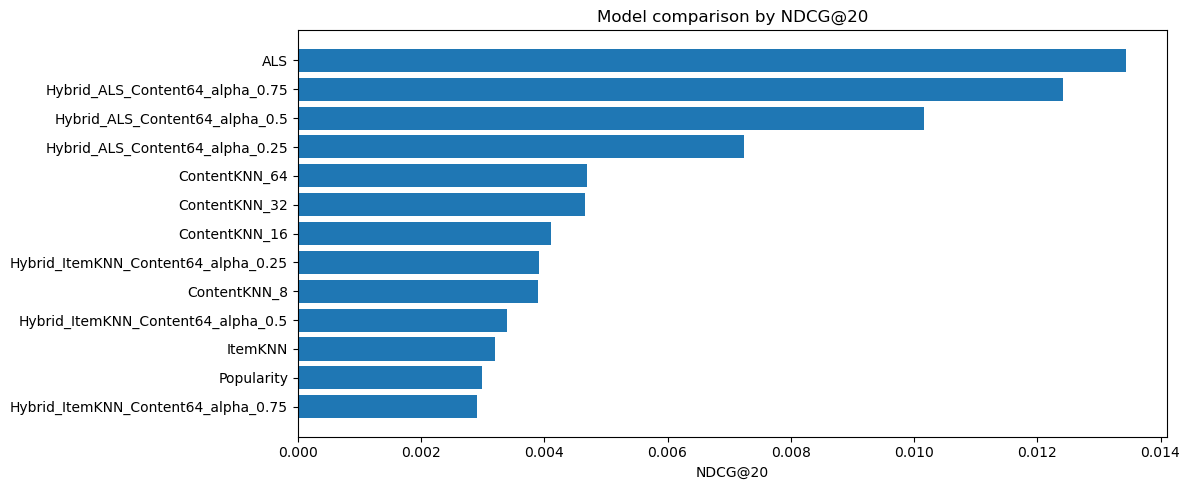

In [28]:
plt.figure(figsize=(12, 5))
plot_df = results_df.sort_values('ndcg@20')
plt.barh(plot_df['model'], plot_df['ndcg@20'])
plt.title('Model comparison by NDCG@20')
plt.xlabel('NDCG@20')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison_ndcg20.png', dpi=180)
plt.show()

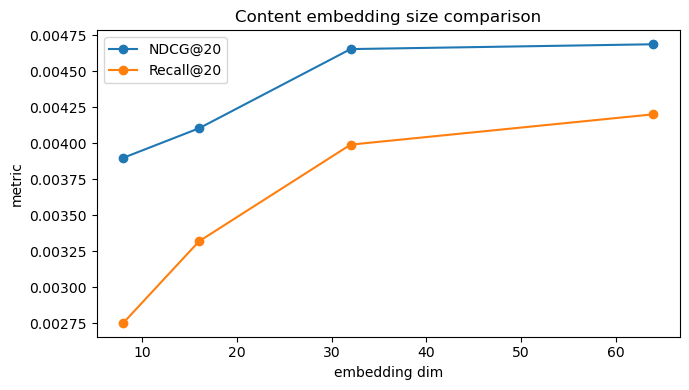

,model,n_eval_users,recall@10,hitrate@10,ndcg@10,cold_recall@10,recall@20,hitrate@20,ndcg@20,cold_recall@20,coverage@20,embedding_dim
3,ContentKNN_8,1200,0.001701,0.038333,0.004119,0.001991,0.002753,0.063333,0.003899,0.003447,0.585981,8
4,ContentKNN_16,1200,0.002208,0.040000,0.004339,0.002114,0.003319,0.066667,0.004105,0.002741,0.505996,16
5,ContentKNN_32,1200,0.002380,0.043333,0.004526,0.001480,0.003991,0.073333,0.004655,0.002614,0.469156,32
6,ContentKNN_64,1200,0.002241,0.038333,0.004275,0.001200,0.004202,0.075000,0.004688,0.001948,0.444554,64


In [29]:
embedding_comparison = results_df[results_df['model'].str.startswith('ContentKNN_')].copy()
embedding_comparison['embedding_dim'] = embedding_comparison['model'].str.extract(r'(\d+)').astype(int)
embedding_comparison = embedding_comparison.sort_values('embedding_dim')
embedding_comparison.to_csv(OUTPUT_DIR / 'embedding_dim_comparison.csv', index=False)

plt.figure(figsize=(7, 4))
plt.plot(embedding_comparison['embedding_dim'], embedding_comparison['ndcg@20'], marker='o', label='NDCG@20')
plt.plot(embedding_comparison['embedding_dim'], embedding_comparison['recall@20'], marker='o', label='Recall@20')
plt.title('Content embedding size comparison')
plt.xlabel('embedding dim')
plt.ylabel('metric')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'embedding_dim_comparison.png', dpi=180)
plt.show()

embedding_comparison

In [30]:
def evaluate_stability(model_name, recommend_func, seeds=(1, 7, 42), sample_size=400): #проверка устойчивости
  rows = []
  base_users = [u for u in relevant_by_user if u in train_user_set]

  for seed in seeds:
      rng = np.random.default_rng(seed)
      n = min(sample_size, len(base_users))
      sampled = rng.choice(base_users, size=n, replace=False).tolist() if n else []
      summary, _ = evaluate_recommender(model_name, recommend_func, sampled, relevant_by_user)
      summary['seed'] = seed
      rows.append(summary)
  return pd.DataFrame(rows)
# сам процесс заключается в том, что происходила проверка через повторную оценку моделей на нескольких случайных подвыборках пользователей
#Если метрики сильно не меняются между seed, значит выводы о качестве моделей не зависят от случайного выбора пользователей для оценки
stability_df = pd.concat([evaluate_stability('Popularity', recommend_popularity), evaluate_stability('ItemKNN', recommend_itemknn), evaluate_stability('ContentKNN_64', content64), evaluate_stability('Hybrid_ItemKNN_Content64_alpha_0.5', make_hybrid_ranker(recommend_itemknn, content64, alpha=0.5))], ignore_index=True)
stability_df.to_csv(OUTPUT_DIR / 'stability_by_seed.csv', index=False)
stability_df

,model,n_eval_users,recall@10,hitrate@10,ndcg@10,recall@20,hitrate@20,ndcg@20,coverage@20,seed
0,Popularity,400,0.000781,0.0175,0.001808,0.003637,0.0675,0.003391,0.005192,1
1,Popularity,400,0.000710,0.0150,0.001475,0.005386,0.0750,0.003939,0.005069,7
2,Popularity,400,0.001274,0.0250,0.002099,0.003932,0.0800,0.003699,0.005934,42
3,ItemKNN,400,0.001645,0.0275,0.002618,0.004429,0.0775,0.003999,0.044010,1
4,ItemKNN,400,0.001759,0.0200,0.002604,0.005741,0.0700,0.004320,0.032761,7
5,ItemKNN,400,0.001166,0.0225,0.002299,0.004100,0.0700,0.003676,0.030535,42
6,ContentKNN_64,400,0.002979,0.0375,0.003615,0.004489,0.0800,0.004547,0.283348,1
7,ContentKNN_64,400,0.003834,0.0450,0.006112,0.005108,0.0650,0.005617,0.282977,7
8,ContentKNN_64,400,0.002244,0.0475,0.004029,0.005739,0.1025,0.005639,0.279268,42
9,Hybrid_ItemKNN_Content64_alpha_0.5,400,0.002348,0.0300,0.002483,0.004665,0.0675,0.003683,0.195080,1


In [31]:
stability_summary = stability_df.groupby('model')[['recall@20', 'ndcg@20', 'hitrate@20', 'coverage@20']].agg(['mean', 'std'])
stability_summary.to_csv(OUTPUT_DIR / 'stability_summary.csv')
stability_summary

recall@20             ndcg@20            \
                                        mean       std      mean       std   
model                                                                        
ContentKNN_64                       0.005112  0.000625  0.005268  0.000624   
Hybrid_ItemKNN_Content64_alpha_0.5  0.004827  0.000699  0.004325  0.001037   
ItemKNN                             0.004757  0.000868  0.003998  0.000322   
Popularity                          0.004319  0.000936  0.003676  0.000275   

                                   hitrate@20           coverage@20            
                                         mean       std        mean       std  
model                                                                          
ContentKNN_64                        0.082500  0.018875    0.281864  0.002256  
Hybrid_ItemKNN_Content64_alpha_0.5   0.066667  0.001443    0.191907  0.003999  
ItemKNN                              0.072500  0.004330    0.035769  0.007224  
Popularity                           0.074167  0.006292    0.005398  0.000468